# Step 2f: scorecards (reads the results of notebooks 02 to 06)

This notebook runs no models and no explainers. It reads the `scorecard.csv` that each explanation notebook saved to `outputs/step2_explain/<family>/`, and lays the results out **within each input-type group**, as agreed in `docs/step2_plan.md`:

| Group | Notebook | Models |
|---|---|---|
| profile stats | 02 | 12 tabular models |
| posting timeline | 03 | CNN, RNN, LSTM, LSTM autoencoder |
| post text | 04 | transformer, word2vec, doc2vec |
| graph, neural | 05 | GCN, GAT, GraphSAGE, R-GCN |
| graph, structure only | 05 | node2vec, DeepWalk, label spreading, belief propagation |
| multimodal | 06 | fusion model |

**There is no composite score and no ranking across groups.** The tasks differ in difficulty (the timelines are almost perfectly separable, the profile stats are not), so a number from one group does not transfer to another. Within a group, models are shown criterion by criterion. Colours in the heatmaps are scaled **within each column of one group**, so they show who is relatively better in that group, not absolute quality; read the numbers.

> If a notebook has not been run yet, its group is skipped with a message.

## 0. Setup and load

In [ ]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 200)
OUT = REPO_ROOT / "outputs" / "step2_explain"

FAMILIES = {
    "tabular": "02",
    "sequences": "03",
    "text": "04",
    "graph": "05",
    "multimodal": "06",
}
GROUP_TITLES = {
    "profile_stats": "Profile stats (12 models)",
    "timeline": "Posting timeline (4 models)",
    "post_text": "Post text (3 models)",
    "gnn": "Graph: neural networks (4 models)",
    "structure_only": "Graph: structure only (4 models)",
    "multimodal": "Multimodal (1 model)",
}
frames, missing = [], []
for fam, num in FAMILIES.items():
    f = OUT / fam / "scorecard.csv"
    if f.exists():
        frames.append(pd.read_csv(f))
    else:
        missing.append(f"{fam} (notebook {num})")
SC = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print("loaded groups:", sorted(SC.group.unique()) if len(SC) else "none")
if missing:
    print("NOT RUN YET:", ", ".join(missing))

loaded groups: ['multimodal', 'post_text', 'profile_stats', 'timeline']
NOT RUN YET: graph (notebook 05)


## 1. Did every model reload correctly?

Each notebook checked that the models it explains reproduce the step-1 predictions before explaining anything. This table collects those checks; every row should say `OK`.

In [2]:
rows = []
for fam in FAMILIES:
    f = OUT / fam / "reload_checks.csv"
    if f.exists():
        rows.append(pd.read_csv(f).assign(notebook_family=fam))
if rows:
    chk = pd.concat(rows, ignore_index=True)
    display(chk.round(6))
    print(
        "all OK"
        if (chk.status == "OK").all()
        else "SOME MODELS DID NOT RELOAD CORRECTLY: do not trust their rows"
    )

,model,max_abs_diff,spearman,status,notebook_family
0,rf,0.000000,1.000000,OK,tabular
1,xgboost,0.000000,1.000000,OK,tabular
2,lightgbm,0.000000,1.000000,OK,tabular
3,svm_rbf,0.000000,1.000000,OK,tabular
4,svm_linear,0.000000,1.000000,OK,tabular
5,pca_logreg,0.000000,1.000000,OK,tabular
6,nmf_logreg,0.000000,1.000000,OK,tabular
7,svd_logreg,0.000000,1.000000,OK,tabular
8,isolation_forest,0.000000,1.000000,OK,tabular
9,lof,0.000000,1.000000,OK,tabular


all OK


## 2. The criteria, in one table per group

Rows are model / method pairs. For each group we pick one **primary** column per criterion so the groups can be read the same way (the full per-criterion tables are in sections 4 to 9):

| Criterion | Primary column |
|---|---|
| Correctness | profile stats: `correctness_rank` · timeline: `correctness_mask_auc` · text: `correctness_marker_top1` · GNN and propagation models: `correctness_ring_edge_auc` or `correctness_same_ring_top3` · embeddings, multimodal: not defined |
| Faithfulness | `faithfulness` (deletion test, in score-std units; 0 = the top-attributed inputs matter no more than random ones) |
| Agreement | `agreement_spearman` between the model's two methods |
| Stability | `stability_noise` (or `stability_drop_word` for text, `stability_drop_item` for label spreading and belief propagation) |

In [3]:
PRIMARY = {
    "correctness": [
        "correctness_rank",
        "correctness_mask_auc",
        "correctness_marker_top1",
        "correctness_ring_edge_auc",
        "correctness_same_ring_top3",
    ],
    "faithfulness": ["faithfulness"],
    "agreement": ["agreement_spearman"],
    "stability": ["stability_noise", "stability_drop_word", "stability_drop_item"],
}


def first_available(df_model_method, names):
    for n in names:
        v = df_model_method.loc[df_model_method.criterion == n, "value"]
        if len(v) and not np.isnan(v.iloc[0]):
            return float(v.iloc[0])
    return np.nan


def summary_table(group):
    d = SC[SC.group == group]
    rows = []
    explainers = d[
        ~d.method.str.contains(" vs ") & ~d.method.str.contains("no explainer")
    ]
    for (model, method), g in explainers.groupby(["model", "method"], sort=False):
        agree = d[
            (d.model == model)
            & d.method.str.contains(" vs ")
            & (d.criterion == "agreement_spearman")
        ]["value"]
        rows.append(
            dict(
                model=model,
                method=method,
                **{
                    k: first_available(g, v)
                    for k, v in PRIMARY.items()
                    if k != "agreement"
                },
                agreement=float(agree.iloc[0]) if len(agree) else np.nan,
            )
        )
    return pd.DataFrame(rows).set_index(["model", "method"])[
        ["correctness", "faithfulness", "agreement", "stability"]
    ]


SUMMARY = {}
for g in GROUP_TITLES:
    if len(SC) and (SC.group == g).any():
        SUMMARY[g] = summary_table(g)
        print(GROUP_TITLES[g])
        display(SUMMARY[g].round(3))

Profile stats (12 models)


correctness  faithfulness  agreement  stability
model             method                                                 
rf                SHAP          0.557         0.586      0.683      0.940
                  LIME          0.491         0.502      0.683      0.850
xgboost           SHAP          0.553         0.657      0.624      0.920
                  LIME          0.454         0.575      0.624      0.790
lightgbm          SHAP          0.631         0.645      0.654      0.920
                  LIME          0.482         0.564      0.654      0.788
svm_rbf           SHAP          0.590         0.516      0.611      0.966
                  LIME          0.460         0.456      0.611      0.811
svm_linear        SHAP          0.524         0.642      0.729      0.969
                  LIME          0.450         0.585      0.729      0.802
pca_logreg        SHAP          0.571         0.464      0.758      0.971
                  LIME          0.516         0.379      0.758      0.884
nmf_logreg        SHAP          0.433         0.534      0.725      0.973
                  LIME          0.429         0.524      0.725      0.769
svd_logreg        SHAP          0.571         0.464      0.758      0.971
                  LIME          0.516         0.379      0.758      0.884
isolation_forest  SHAP          0.174         0.938      0.152      0.935
                  LIME          0.037         0.318      0.152      0.813
lof               SHAP          0.198         0.771     -0.004      0.947
                  LIME         -0.041         0.099     -0.004      0.785
one_class_svm     SHAP          0.150         1.185     -0.077      0.958
                  LIME         -0.006         0.098     -0.077      0.748
autoencoder_dense SHAP          0.200         0.522      0.011      0.952
                  LIME          0.110         0.115      0.011      0.744

Posting timeline (4 models)


correctness  faithfulness  agreement  stability
model            method                                                               
cnn1d            Grad-CAM                    0.732         0.301      0.121      0.980
                 Integrated Gradients        0.987         0.815      0.121      0.617
rnn              Integrated Gradients        0.943         0.691      0.163      0.205
                 GradientSHAP                0.634         0.224      0.163      0.963
lstm             Integrated Gradients        0.966         0.919      0.295      0.510
                 GradientSHAP                0.836         0.406      0.295      0.697
autoencoder_lstm Integrated Gradients        0.990         0.980      0.483      0.622
                 GradientSHAP                0.981         0.896      0.483      0.488

Post text (3 models)


correctness  faithfulness  agreement  stability
model           method                                                 
transformer     SHAP          0.983         1.023      0.480      0.951
                LIME          0.983         1.025      0.480      0.716
word2vec_logreg SHAP          0.900         0.863      0.498      0.966
                LIME          0.900         0.770      0.498      0.849
doc2vec_logreg  SHAP          1.000         0.584      0.410      0.547
                LIME          1.000         0.527      0.410      0.702

Multimodal (1 model)


correctness  faithfulness  agreement  stability
model             method                                                            
multimodal_fusion Block Shapley              NaN         0.171      0.458      0.988
                  Drop-one ablation          NaN         0.224      0.458      0.990

## 3. Heatmaps within each group

Colour = rank within the column (green = best in the group, red = worst); numbers are the values. A blank cell means the criterion is not defined for that model.

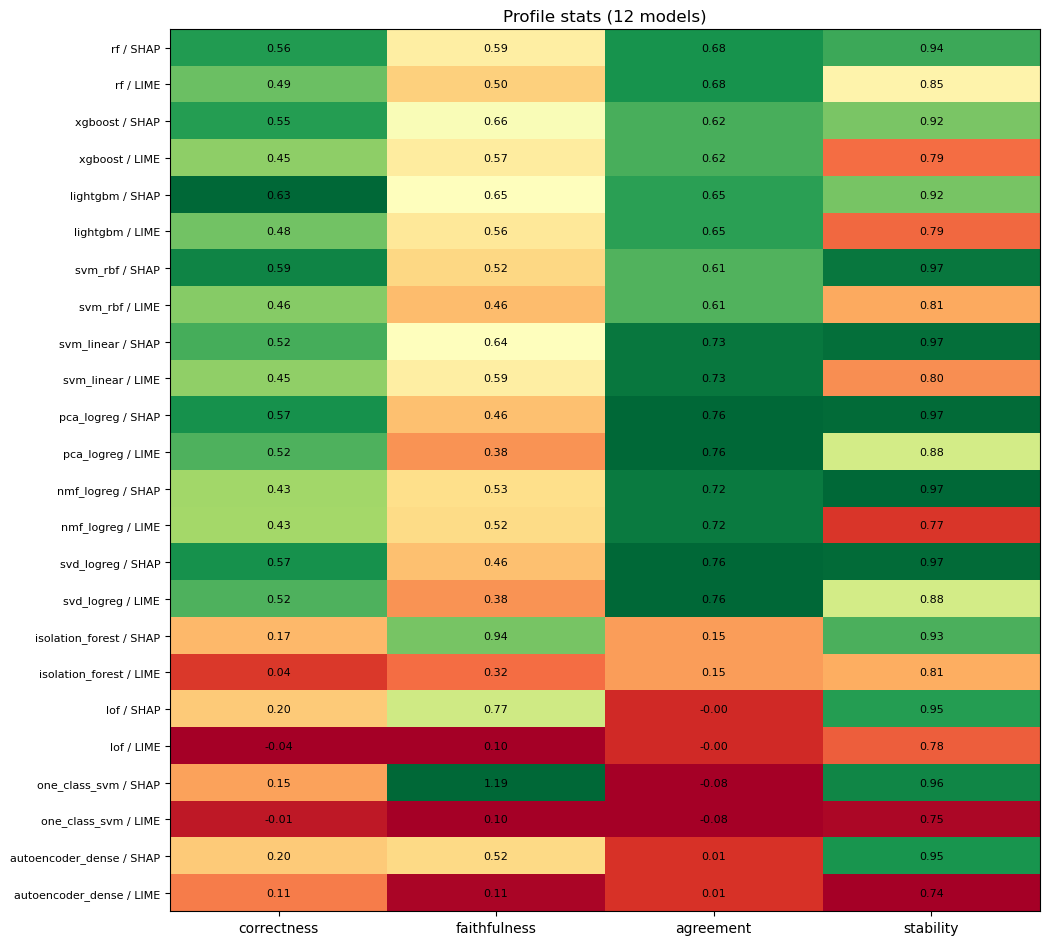

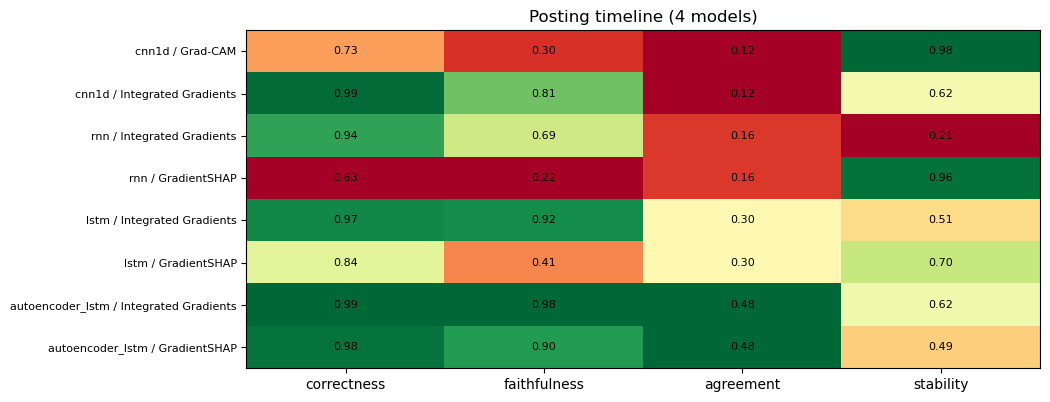

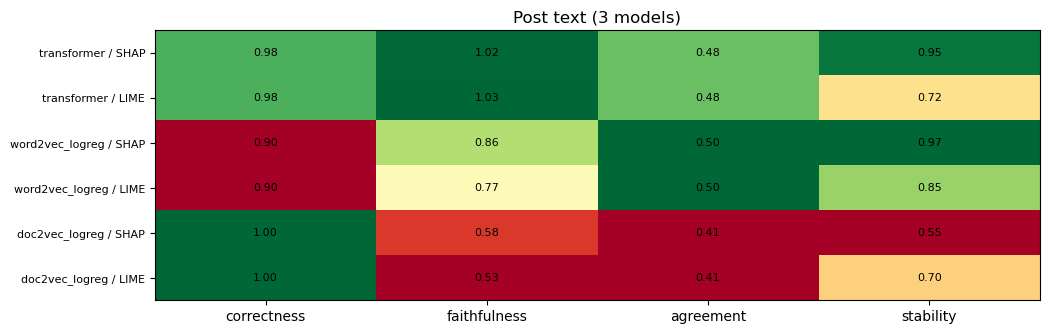

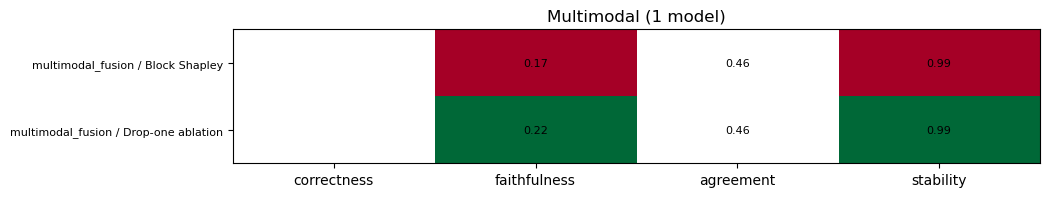

In [4]:
def heatmap(tbl, title):
    data = tbl.to_numpy(dtype=float)
    z = np.full_like(data, np.nan)
    for j in range(data.shape[1]):
        col = data[:, j]
        ok = ~np.isnan(col)
        if ok.sum() > 1 and np.ptp(col[ok]) > 0:
            z[ok, j] = (col[ok] - col[ok].min()) / np.ptp(col[ok])
        elif ok.sum() == 1:
            z[ok, j] = 0.5
    fig, ax = plt.subplots(figsize=(1.9 * data.shape[1] + 3, 0.34 * len(tbl) + 1.4))
    ax.imshow(z, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels(tbl.columns)
    ax.set_yticks(range(len(tbl)))
    ax.set_yticklabels([f"{m} / {me}" for m, me in tbl.index], fontsize=8)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if not np.isnan(data[i, j]):
                ax.text(j, i, f"{data[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


for g, t in SUMMARY.items():
    heatmap(t, GROUP_TITLES[g])

## 4. Reading the patterns

The plan (`docs/step2_plan.md`, section 2) says how to read combinations of criteria. This table flags them **relative to the group median** (so a flag means "better or worse than its peers", not "good" or "bad" in absolute terms). Treat it as a pointer to what to look at, not a verdict.

| Flag | Meaning |
|---|---|
| `shortcut?` | faithfulness above the group median but correctness below: the explainer describes the model well, but the model may rely on something other than the planted signal |
| `shared blind spot?` | agreement above the median but correctness below: both methods may miss the same thing |
| `unstable` | stability below the group median |
| `unfaithful` | faithfulness below the group median |

In [5]:
def flags(tbl):
    med = tbl.median(numeric_only=True)
    out = []
    for idx, r in tbl.iterrows():
        f = []
        if r.faithfulness > med.faithfulness and r.correctness < med.correctness:
            f.append("shortcut?")
        if r.agreement > med.agreement and r.correctness < med.correctness:
            f.append("shared blind spot?")
        if r.stability < med.stability:
            f.append("unstable")
        if r.faithfulness < med.faithfulness:
            f.append("unfaithful")
        out.append(", ".join(f))
    return pd.Series(out, index=tbl.index, name="flags")


for g, t in SUMMARY.items():
    if len(t) > 2:
        print(GROUP_TITLES[g])
        display(pd.concat([t.round(3), flags(t)], axis=1))

Profile stats (12 models)


correctness  faithfulness  agreement  stability                                    flags
model             method                                                                                          
rf                SHAP          0.557         0.586      0.683      0.940                                         
                  LIME          0.491         0.502      0.683      0.850                     unstable, unfaithful
xgboost           SHAP          0.553         0.657      0.624      0.920                                         
                  LIME          0.454         0.575      0.624      0.790                      shortcut?, unstable
lightgbm          SHAP          0.631         0.645      0.654      0.920                                         
                  LIME          0.482         0.564      0.654      0.788                                 unstable
svm_rbf           SHAP          0.590         0.516      0.611      0.966                               unfaithful
                  LIME          0.460         0.456      0.611      0.811                     unstable, unfaithful
svm_linear        SHAP          0.524         0.642      0.729      0.969                                         
                  LIME          0.450         0.585      0.729      0.802  shortcut?, shared blind spot?, unstable
pca_logreg        SHAP          0.571         0.464      0.758      0.971                               unfaithful
                  LIME          0.516         0.379      0.758      0.884                     unstable, unfaithful
nmf_logreg        SHAP          0.433         0.534      0.725      0.973            shortcut?, shared blind spot?
                  LIME          0.429         0.524      0.725      0.769  shortcut?, shared blind spot?, unstable
svd_logreg        SHAP          0.571         0.464      0.758      0.971                               unfaithful
                  LIME          0.516         0.379      0.758      0.884                     unstable, unfaithful
isolation_forest  SHAP          0.174         0.938      0.152      0.935                                shortcut?
                  LIME          0.037         0.318      0.152      0.813                     unstable, unfaithful
lof               SHAP          0.198         0.771     -0.004      0.947                                shortcut?
                  LIME         -0.041         0.099     -0.004      0.785                     unstable, unfaithful
one_class_svm     SHAP          0.150         1.185     -0.077      0.958                                shortcut?
                  LIME         -0.006         0.098     -0.077      0.748                     unstable, unfaithful
autoencoder_dense SHAP          0.200         0.522      0.011      0.952                               unfaithful
                  LIME          0.110         0.115      0.011      0.744                     unstable, unfaithful

Posting timeline (4 models)


correctness  faithfulness  agreement  stability                           flags
model            method                                                                                               
cnn1d            Grad-CAM                    0.732         0.301      0.121      0.980                      unfaithful
                 Integrated Gradients        0.987         0.815      0.121      0.617                        unstable
rnn              Integrated Gradients        0.943         0.691      0.163      0.205            unstable, unfaithful
                 GradientSHAP                0.634         0.224      0.163      0.963                      unfaithful
lstm             Integrated Gradients        0.966         0.919      0.295      0.510                        unstable
                 GradientSHAP                0.836         0.406      0.295      0.697  shared blind spot?, unfaithful
autoencoder_lstm Integrated Gradients        0.990         0.980      0.483      0.622                                
                 GradientSHAP                0.981         0.896      0.483      0.488                        unstable

Post text (3 models)


correctness  faithfulness  agreement  stability                           flags
model           method                                                                                 
transformer     SHAP          0.983         1.023      0.480      0.951                                
                LIME          0.983         1.025      0.480      0.716                        unstable
word2vec_logreg SHAP          0.900         0.863      0.498      0.966   shortcut?, shared blind spot?
                LIME          0.900         0.770      0.498      0.849  shared blind spot?, unfaithful
doc2vec_logreg  SHAP          1.000         0.584      0.410      0.547            unstable, unfaithful
                LIME          1.000         0.527      0.410      0.702            unstable, unfaithful

## 5. Profile stats: full tables and credit by feature group

In [6]:
def full_table(group, order=None):
    d = SC[SC.group == group]
    if d.empty:
        print("(not run yet)")
        return
    t = d.pivot_table(index=["model", "method"], columns="criterion", values="value")
    display(t.round(3))


full_table("profile_stats")
f = OUT / "tabular" / "credit_by_feature_group.csv"
if f.exists():
    print(
        "Share of total |attribution| given to each kind of feature (planted truth: 6 informative features, no credit to the rest)"
    )
    display(pd.read_csv(f).set_index(["model", "method"]).round(3))

criterion                       agreement_spearman  agreement_top3  correctness_informative_share  correctness_rank  correctness_top5_precision  faithfulness  repeatability_seed  \
model             method                                                                                                                                                            
autoencoder_dense LIME                         NaN             NaN                          0.518             0.110                       0.527         0.115               0.599   
                  SHAP                         NaN             NaN                          0.563             0.200                       0.581         0.522               0.982   
                  SHAP vs LIME               0.011           0.322                            NaN               NaN                         NaN           NaN                 NaN   
isolation_forest  LIME                         NaN             NaN                          0.488             0.037                       0.496         0.318               0.741   
                  SHAP                         NaN             NaN                          0.518             0.174                       0.549         0.938               0.995   
                  SHAP vs LIME               0.152           0.369                            NaN               NaN                         NaN           NaN                 NaN   
lightgbm          LIME                         NaN             NaN                          0.832             0.482                       0.783         0.564               0.697   
                  SHAP                         NaN             NaN                          0.861             0.631                       0.832         0.645               1.000   
                  SHAP vs LIME               0.654           0.800                            NaN               NaN                         NaN           NaN                 NaN   
lof               LIME                         NaN             NaN                          0.457            -0.041                       0.460         0.099               0.668   
                  SHAP                         NaN             NaN                          0.491             0.198                       0.557         0.771               0.978   
                  SHAP vs LIME              -0.004           0.258                            NaN               NaN                         NaN           NaN                 NaN   
nmf_logreg        LIME                         NaN             NaN                          0.879             0.429                       0.783         0.524               0.731   
                  SHAP                         NaN             NaN                          0.947             0.433                       0.789         0.534               0.979   
                  SHAP vs LIME               0.725           0.880                            NaN               NaN                         NaN           NaN                 NaN   
one_class_svm     LIME                         NaN             NaN                          0.481            -0.006                       0.463         0.098               0.614   
                  SHAP                         NaN             NaN                          0.509             0.150                       0.524         1.185               0.987   
                  SHAP vs LIME              -0.077           0.269                            NaN               NaN                         NaN           NaN                 NaN   
pca_logreg        LIME                         NaN             NaN                          0.639             0.516                       0.691         0.379               0.855   
                  SHAP                         NaN             NaN                          0.690             0.571                       0.707         0.464               0.991   
                  

Share of total |attribution| given to each kind of feature (planted truth: 6 informative features, no credit to the rest)


informative (6)  proxy posts_per_week  decoys (2)  noise (3)
model             method                                                              
rf                SHAP              0.780                 0.131       0.030      0.059
                  LIME              0.765                 0.138       0.035      0.062
xgboost           SHAP              0.804                 0.074       0.049      0.072
                  LIME              0.806                 0.083       0.042      0.070
lightgbm          SHAP              0.861                 0.071       0.022      0.046
                  LIME              0.832                 0.067       0.037      0.064
svm_rbf           SHAP              0.786                 0.099       0.037      0.078
                  LIME              0.757                 0.140       0.039      0.064
svm_linear        SHAP              0.868                 0.086       0.013      0.033
                  LIME              0.802                 0.095       0.039      0.064
pca_logreg        SHAP              0.690                 0.106       0.111      0.093
                  LIME              0.639                 0.151       0.120      0.090
nmf_logreg        SHAP              0.947                 0.001       0.038      0.015
                  LIME              0.879                 0.017       0.055      0.050
svd_logreg        SHAP              0.690                 0.106       0.111      0.093
                  LIME              0.639                 0.151       0.120      0.090
isolation_forest  SHAP              0.518                 0.077       0.136      0.269
                  LIME              0.488                 0.144       0.177      0.191
lof               SHAP              0.491                 0.055       0.144      0.311
                  LIME              0.457                 0.194       0.170      0.179
one_class_svm     SHAP              0.509                 0.040       0.143      0.308
                  LIME              0.481                 0.122       0.158      0.239
autoencoder_dense SHAP              0.563                 0.018       0.131      0.288
                  LIME              0.518                 0.115       0.166      0.202

## 6. Posting timeline: full table and timing probe

In [7]:
full_table("timeline")
f = OUT / "sequences" / "timing_probe.csv"
if f.exists():
    print("AUC when the hours of each test series are shuffled")
    display(pd.read_csv(f).set_index("model").round(3))

criterion                                              agreement_spearman  agreement_top10  correctness_mask_auc  correctness_mask_auc_bot  correctness_mask_auc_troll  correctness_mass_inside  \
model            method                                                                                                                                                                           
autoencoder_lstm GradientSHAP                                         NaN              NaN                 0.981                     0.973                       0.989                    0.601   
                 Integrated Gradients                                 NaN              NaN                 0.990                     0.986                       0.994                    0.777   
                 Integrated Gradients vs GradientSHAP               0.483            0.667                   NaN                       NaN                         NaN                      NaN   
cnn1d            Grad-CAM                                             NaN              NaN                 0.732                     0.480                       0.985                    0.219   
                 Grad-CAM vs Integrated Gradients                   0.121            0.296                   NaN                       NaN                         NaN                      NaN   
                 Integrated Gradients                                 NaN              NaN                 0.987                     0.980                       0.994                    0.839   
lstm             GradientSHAP                                         NaN              NaN                 0.836                     0.866                       0.806                    0.501   
                 Integrated Gradients                                 NaN              NaN                 0.966                     0.977                       0.954                    0.750   
                 Integrated Gradients vs GradientSHAP               0.295            0.420                   NaN                       NaN                         NaN                      NaN   
rnn              GradientSHAP                                         NaN              NaN                 0.634                     0.592                       0.675                    0.335   
                 Integrated Gradients                                 NaN              NaN                 0.943                     0.956                       0.930                    0.600   
                 Integrated Gradients vs GradientSHAP               0.163            0.284                   NaN                       NaN                         NaN                      NaN   

criterion                                              faithfulness  repeatability_seed  seconds_per_explanation  stability_noise  
model            method                                                                                                            
autoencoder_lstm GradientSHAP                                 0.896               0.453                    0.005            0.488  
                 Integrated Gradients                         0.980               1.000                    0.028            0.622  
                 Integrated Gradients vs GradientSHAP           NaN                 NaN                      NaN              NaN  
cnn1d            Grad-CAM                                     0.301               1.000                    0.000            0.980  
                 Grad-CAM vs Integrated Gradients               NaN                 NaN                      NaN              NaN  
                 Integrated Gradients                         0.815               1.000                    0.005            0.617  
lstm             GradientSHAP                                 0.406               0.659                    0.002            0.697  
                 Integrated Gradients                         0.919              

AUC when the hours of each test series are shuffled


,auc_original,auc_shuffled_hours,auc_drop
model,,,
cnn1d,1.000,0.997,0.002
rnn,0.886,0.882,0.004
lstm,1.000,0.997,0.003
autoencoder_lstm,0.988,0.988,-0.000


## 7. Post text: full table and reliance probe

In [8]:
full_table("post_text")
f = OUT / "text" / "reliance_probe.csv"
if f.exists():
    print("Post-level AUC with the decoy / the markers removed")
    display(pd.read_csv(f).set_index("model").round(3))

criterion                             agreement_spearman  agreement_top3  correctness_marker_mass  correctness_marker_top1  faithfulness  repeatability_seed  seconds_per_explanation  shortcut_mass  \
model           method                                                                                                                                                                                 
doc2vec_logreg  LIME                                 NaN             NaN                    0.830                    1.000         0.527               0.734                    0.184          0.562   
                SHAP                                 NaN             NaN                    0.840                    1.000         0.584               0.571                    0.111          0.531   
                SHAP vs LIME                       0.410           0.583                      NaN                      NaN           NaN                 NaN                      NaN            NaN   
                model (no explainer)                 NaN             NaN                      NaN                      NaN           NaN                 NaN                      NaN            NaN   
transformer     LIME                                 NaN             NaN                    0.724                    0.983         1.025               0.857                    0.050          0.865   
                SHAP                                 NaN             NaN                    0.512                    0.983         1.023               0.962                    0.027          0.533   
                SHAP vs LIME                       0.480           0.643                      NaN                      NaN           NaN                 NaN                      NaN            NaN   
                model (no explainer)                 NaN             NaN                      NaN                      NaN           NaN                 NaN                      NaN            NaN   
word2vec_logreg LIME                                 NaN             NaN                    0.424                    0.900         0.770               0.881                    0.019          0.774   
                SHAP                                 NaN             NaN                    0.391                    0.900         0.863               0.980                    0.009          0.577   
                SHAP vs LIME                       0.498           0.544                      NaN                      NaN           NaN                 NaN                      NaN            NaN   
                model (no explainer)                 NaN             NaN                      NaN                      NaN           NaN                 NaN                      NaN            NaN   

criterion                             shortcut_model_effect  shortcut_top1  stability_drop_word  
model           method                                                                           
doc2vec_logreg  LIME                                    NaN            1.0                0.702  
                SHAP                                    NaN            1.0                0.547  
                SHAP vs LIME                            NaN            NaN                  NaN  
                model (no explainer)                  0.834            NaN                  NaN  
transformer     LIME                                    NaN            1.0                0.716  
                SHAP                                    NaN            1.0                0.951  
                SHAP vs LIME                            NaN            NaN                  NaN  
                model (no explainer)                  2.254            NaN                  NaN  
word2vec_logreg LIME                                    NaN            1.0                0.849  
                SHAP                                    NaN            1.0                0.966  
                SHAP vs

Post-level AUC with the decoy / the markers removed


,auc_original,auc_without_decoy,auc_without_markers,drop_without_decoy,drop_without_markers
model,,,,,
transformer,0.648,0.662,0.486,-0.013,0.162
word2vec_logreg,0.606,0.629,0.495,-0.023,0.111
doc2vec_logreg,0.663,0.661,0.510,0.001,0.153


## 8. Graph: full tables, reliance probe, embedding probe

In [9]:
full_table("gnn")
full_table("structure_only")
for f, title in [
    (
        OUT / "graph" / "reliance_probe.csv",
        "How much each model uses the graph and degree",
    ),
    (
        OUT / "graph" / "embedding_probe.csv",
        "What the node2vec / DeepWalk dimensions encode",
    ),
]:
    if f.exists():
        print(title)
        display(pd.read_csv(f).set_index("model").round(3))

(not run yet)
(not run yet)


## 9. Multimodal

In [10]:
full_table("multimodal")
for name, title in [
    ("coalition_auc", "AUC of the fusion model with only some blocks present"),
    ("block_vs_answer_key", "Do the block values follow the planted signals?"),
]:
    f = OUT / "multimodal" / f"{name}.csv"
    if f.exists():
        print(title)
        display(pd.read_csv(f).set_index(pd.read_csv(f).columns[0]).round(3))

criterion                              agreement_spearman  agreement_top1  faithfulness  faithfulness_bot  faithfulness_human  faithfulness_troll  repeatability_seed  seconds_per_explanation  \
model             method                                                                                                                                                                         
multimodal_fusion Block Shapley                       NaN             NaN         0.171             0.272               0.095               0.410                 1.0                      0.0   
                  Drop-one ablation                   NaN             NaN         0.224             0.347               0.145               0.451                 1.0                      0.0   
                  Shapley vs ablation               0.458           0.551           NaN               NaN                 NaN                 NaN                 NaN                      NaN   

criterion                              stability_noise  
model             method                                
multimodal_fusion Block Shapley                  0.988  
                  Drop-one ablation              0.990  
                  Shapley vs ablation              NaN

AUC of the fusion model with only some blocks present


,test_auc
present,
(nothing),0.500
tab,0.766
text,0.873
graph,0.422
tab+text,0.900
tab+graph,0.767
text+graph,0.932
tab+text+graph,0.948


Do the block values follow the planted signals?


,text_vs_marker_count,text_vs_decoy_count,graph_auc_for_troll,graph_vs_degree,tab_vs_planted_logit
method,,,,,
Block Shapley,0.765,0.535,0.506,0.004,0.764
Drop-one ablation,0.751,0.492,0.507,0.006,0.773


## 10. SHAP versus LIME, wherever both were used

Both methods were used for the 12 profile-stats models, the 3 text models and the 2 embedding models. The table averages each criterion over those models, per method. This is the one cross-model comparison the design allows, because it compares *methods*, not models.

In [11]:
rows = []
for g in ["profile_stats", "post_text", "structure_only"]:
    d = SC[(SC.group == g) & SC.method.isin(["SHAP", "LIME"])]
    if d.empty:
        continue
    d = d[
        d.criterion.isin(
            [
                "correctness_rank",
                "correctness_marker_top1",
                "faithfulness",
                "stability_noise",
                "stability_drop_word",
                "repeatability_seed",
                "seconds_per_explanation",
            ]
        )
    ]
    t = d.pivot_table(
        index="method", columns="criterion", values="value", aggfunc="mean"
    )
    t.index = [f"{g}: {m}" for m in t.index]
    rows.append(t)
if rows:
    display(pd.concat(rows).round(3))

criterion,correctness_rank,faithfulness,repeatability_seed,seconds_per_explanation,stability_noise,correctness_marker_top1,stability_drop_word
profile_stats: LIME,0.325,0.383,0.726,0.022,0.806,NaN,NaN
profile_stats: SHAP,0.429,0.660,0.988,0.087,0.952,NaN,NaN
post_text: LIME,NaN,0.774,0.824,0.084,NaN,0.961,0.756
post_text: SHAP,NaN,0.823,0.838,0.049,NaN,0.961,0.821


## 11. Answering the project question

The question is *how explainable are the partial and black-box models for detecting anonymous fake accounts?* Using the tables above, write down for each group:

1. **Which models gave explanations you would trust** (high faithfulness, stable), and which of those also found the planted signal.
2. **Which models are explainable but wrong for the wrong reasons** (the `shortcut?` flag): the explanation is faithful, but the model's evidence is the decoy hashtag, node degree, post volume or a proxy feature.
3. **Which models resisted explanation** (low faithfulness or low stability), and whether the cause is the model (for example, doc2vec's inference, LOF's local density) or the explainer (sampling noise: compare `repeatability_seed`).
4. **What a method comparison says**: does SHAP or LIME do better, and does the answer depend on the model family?

Caveats to state with the results: explainability here is **measured** by agreement with a planted truth and by perturbation tests, not by whether a person finds the explanation understandable (there was no user study); the data are synthetic and cleaner than real data; and the known issues listed in `docs/step2_plan.md` (belief propagation's inverted scores, the duplicate SVD model, the weak models, the data confounds) apply.